# PDO Cell Painting pipeline figure

A publication-style schematic drawn entirely from matplotlib polygons. Panels are lettered A–E (in the order below) for the figure caption:

1. **Patient tumor resection, organoid culture & drug treatment** (one continuous process):
   patient → resected tumors of several types → dissociation into single cells → plating in a 96-well
   plate → one well magnified (Matrigel ring, top and side views) → assay timeline (Day 0 seeding,
   Days 1–3 organoid formation, Days 4–5 drug treatment, Day 6 Cell Painting) → arrow to the microscope
2. **Cell Painting + high-content volumetric imaging**: AGP, DNA, ER and Mito z-stacks
3. **2.5D/3D segmentation**: nuclei, cells, cytoplasm and whole-organoid masks
4. **3D feature extraction**: handcrafted features are measured for every compartment × channel;
   nuclei, cell and cytoplasm profiles are joined into single-cell profiles, organoid profiles stay separate;
   each feature type is illustrated with its tile from the hand-drawn feature-type illustration (two rows);
   the ZEDprofiler logo marks the panel
5. **Image-based profiling**: quality control (coSMicQC) → normalize → feature selection → aggregate (per well)
   → consensus (per drug); each step card carries its tool's logo (coSMicQC or pycytominer)

The figure is sized for a 180 mm double-column journal width with 6–9 pt text, and is exported as
vector PDF/SVG (editable text) plus a 600 dpi PNG.

The mini-ring assay format and timeline in panel 1 follow Phan *et al.*, *Commun. Biol.* **2**, 78 (2019);
cite that paper if you use this panel.

**Requires:** `numpy`, `matplotlib`, `scipy`

> The feature-type tiles come from the feature-type illustration (`feature_types_illustration_path`),
> and the logos from `figures/workflow_figures/assets/logos/`. All micrographs and profiling schematics
> are synthetic.
>
> For the synthetic channel images: To use real data, replace the arrays returned by
> `channel_images()` with your own 2D max-projections scaled to 0–1 (see the note in that section).

In [1]:
import pathlib

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Polygon, RegularPolygon
from notebook_init_utils.notebook_init_utils import init_notebook
from scipy.ndimage import gaussian_filter
from scipy.spatial import Voronoi

root_dir, in_notebook = init_notebook()

In [ ]:
output_figure_file_path = pathlib.Path(
    f"{root_dir}/figures/assembled_figures/figures/final_full_figure_pdo_workflow.png"
)
output_figure_file_path.parent.mkdir(parents=True, exist_ok=True)

# raster images used in the figure
image_dir = pathlib.Path(f"{root_dir}/figures/assembled_figures/assets/images")
feature_types_illustration_path = pathlib.Path(
    f"{root_dir}/figures/assembled_figures/imported_media/Feature_types_wide.png"
)

# software logos (each project's own logo, from its GitHub repo)
LOGO_DIR = pathlib.Path(f"{root_dir}/figures/assembled_figures/assets/logos")
COSMICQC_LOGO = LOGO_DIR / "cosmicqc_icon.png"
PYCYTOMINER_LOGO = LOGO_DIR / "pycytominer_icon.png"
ZEDPROFILER_LOGO = LOGO_DIR / "zedprofiler_icon.png"

## Settings
Fonts fall back from Arial → Helvetica → Liberation Sans → DejaVu Sans, depending on what is installed.
`rng` fixes the random organoid layout; change the seed for a different arrangement.
Drawing coordinates are in abstract units on a `W × H` canvas; the figure is scaled to `FIG_W_IN` inches wide.

In [3]:
mpl.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"],
        "pdf.fonttype": 42,  # editable TrueType text in PDF
        "ps.fonttype": 42,
        "svg.fonttype": "none",  # keep text as text in SVG
    }
)

rng = np.random.default_rng(7)

W, H = 20.0, 7.8  # drawing units (top two rows)
Y_MIN = -12.25  # starting canvas bottom; build_figure() trims it to the content
FIG_W_IN = 180 / 25.4  # 180 mm double-column width
INK = "#222222"
GREY = "#6b6b6b"
LIGHT = "#eceef1"
SLATE = "#5b6b82"  # organoids, drug, dose gradient
MATRIGEL = "#e3d9c6"
MEDIUM = "#f6f7f9"
DRUG = "#c9d0db"  # medium containing drug
LW = 0.7  # standard stroke (pt)
SEG_CMAP = plt.get_cmap("cividis")

FS_TITLE, FS_LABEL, FS_SMALL = 11, 9, 8
HEAD_H = 0.65  # height of every panel's header bar
OUT_STEM = "pdo_pipeline_figure"  # output file name (without extension)

## Polygon helpers
Every shape in the figure is a `Polygon`: bevelled boxes (`chamfer`), circles (`circle`) and arrows (`arrow_poly`).

In [4]:
def chamfer(x, y, w, h, c=0.1):
    """Rectangle with small cut corners."""
    return np.array(
        [
            (x + c, y),
            (x + w - c, y),
            (x + w, y + c),
            (x + w, y + h - c),
            (x + w - c, y + h),
            (x + c, y + h),
            (x, y + h - c),
            (x, y + c),
        ]
    )


def circle(cx, cy, r, n=64):
    t = np.linspace(0, 2 * np.pi, n, endpoint=False)
    return np.c_[cx + r * np.cos(t), cy + r * np.sin(t)]


def poly(ax, verts, fc="none", ec=INK, lw=LW, z=3, closed=True, **kw):
    p = Polygon(
        verts, closed=closed, fc=fc, ec=ec, lw=lw, zorder=z, joinstyle="miter", **kw
    )
    ax.add_patch(p)
    return p


def arrow_poly(p0, p1, w=0.1, hw=0.3, hl=0.26):
    p0, p1 = np.asarray(p0, float), np.asarray(p1, float)
    u = (p1 - p0) / np.linalg.norm(p1 - p0)
    n = np.array([-u[1], u[0]])
    a = p1 - u * hl
    return np.array(
        [
            p0 + n * w / 2,
            a + n * w / 2,
            a + n * hw / 2,
            p1,
            a - n * hw / 2,
            a - n * w / 2,
            p0 - n * w / 2,
        ]
    )


def arrow(ax, p0, p1, color=INK, z=8, **kw):
    poly(ax, arrow_poly(p0, p1, **kw), fc=color, ec="none", z=z)


def bar(ax, p0, p1, w=0.08, color=INK, z=8):
    """Straight polygon segment, extended by w/2 at both ends so joints close cleanly."""
    p0, p1 = np.asarray(p0, float), np.asarray(p1, float)
    u = (p1 - p0) / np.linalg.norm(p1 - p0)
    n = np.array([-u[1], u[0]]) * w / 2
    a, b = p0 - u * w / 2, p1 + u * w / 2
    poly(ax, [a + n, b + n, b - n, a - n], fc=color, ec="none", z=z)


def connector(ax, pts, w=0.08, hw=0.24, hl=0.18, color=INK, z=8):
    """Multi-segment polygon arrow through the points in `pts`."""
    for a, b in zip(pts[:-2], pts[1:-1]):
        bar(ax, a, b, w, color, z)
    arrow(ax, pts[-2], pts[-1], color, z, w=w, hw=hw, hl=hl)


def text(
    ax,
    x,
    y,
    s,
    size=FS_LABEL,
    color=INK,
    weight="normal",
    ha="center",
    va="center",
    **kw,
):
    ax.text(
        x,
        y,
        s,
        fontsize=size,
        color=color,
        weight=weight,
        ha=ha,
        va=va,
        zorder=20,
        linespacing=1.1,
        **kw,
    )

## Organoid geometry
One organoid is generated here and reused in the imaging and segmentation panels so they match:
a wobbly outline (`BLOB`), cell centres (`SEEDS`), Voronoi cell polygons (`CELLS`) and irregular nuclei (`NUCLEI`).
Label colours are sampled from the colourblind-safe **cividis** colormap.

In [5]:
def r_fun(th):
    return 0.72 * (1 + 0.07 * np.sin(3 * th + 0.4) + 0.05 * np.cos(5 * th + 1.1))


def sample_seeds(n=26, min_d=0.17):
    seeds = []
    while len(seeds) < n:
        p = rng.uniform(-0.8, 0.8, 2)
        rho, th = np.hypot(*p), np.arctan2(p[1], p[0])
        if rho < r_fun(th) - 0.07 and all(np.hypot(*(p - q)) > min_d for q in seeds):
            seeds.append(p)
    return np.array(seeds)


SEEDS = sample_seeds()
THETA = np.linspace(0, 2 * np.pi, 220, endpoint=False)
BLOB = np.c_[r_fun(THETA) * np.cos(THETA), r_fun(THETA) * np.sin(THETA)]
LABEL_COLORS = [SEG_CMAP(v) for v in rng.uniform(0.12, 0.95, len(SEEDS))]


def voronoi_polys(seeds):
    far = np.array([[-10, -10], [10, -10], [10, 10], [-10, 10]])
    vor = Voronoi(np.vstack([seeds, far]))
    out = []
    for i in range(len(seeds)):
        v = vor.vertices[vor.regions[vor.point_region[i]]]
        c = v.mean(axis=0)
        out.append(v[np.argsort(np.arctan2(v[:, 1] - c[1], v[:, 0] - c[0]))])
    return out


CELLS = voronoi_polys(SEEDS)


def nucleus_poly(c, k=11):
    a, b = rng.uniform(0.06, 0.085), rng.uniform(0.045, 0.065)
    rot = rng.uniform(0, np.pi)
    t = np.linspace(0, 2 * np.pi, k, endpoint=False)
    rr = 1 + rng.normal(0, 0.08, k)
    x, y = a * rr * np.cos(t), b * rr * np.sin(t)
    return (
        np.c_[x * np.cos(rot) - y * np.sin(rot), x * np.sin(rot) + y * np.cos(rot)] + c
    )


NUCLEI = [nucleus_poly(s) for s in SEEDS]


def to_frame(uv, x, y, s):
    uv = np.asarray(uv)
    return np.c_[x + (uv[:, 0] + 1) / 2 * s, y + (uv[:, 1] + 1) / 2 * s]

## Cell Painting channels
Synthetic grayscale images built from the same geometry: membranes (AGP), nuclei (DNA), perinuclear rings (ER) and punctate signal (Mito).

**To use real images:** replace this function with one that returns a dict
`{"AGP": array, "DNA": array, "ER": array, "Mito": array}` of 2D arrays scaled to 0–1.

In [6]:
def channel_images(n=300):
    g = np.linspace(-1, 1, n)
    uu, vv = np.meshgrid(g, g)
    rho, th = np.hypot(uu, vv), np.arctan2(vv, uu)
    r = r_fun(th)
    inside = 1 / (1 + np.exp(-(r - rho) / 0.015))
    rim = np.exp(-(((rho - r) / 0.03) ** 2))
    d = np.sort(
        np.hypot(
            uu[None] - SEEDS[:, 0, None, None], vv[None] - SEEDS[:, 1, None, None]
        ),
        axis=0,
    )
    d1, d2 = d[0], d[1]
    membrane = np.exp(-(((d2 - d1) / 0.022) ** 2))
    nuc = np.exp(-((d1 / 0.06) ** 4))
    speck = gaussian_filter(rng.random((n, n)), 1.3)
    speck = ((speck - speck.min()) / np.ptp(speck)) ** 5 * 3
    bg = gaussian_filter(rng.random((n, n)), 1) * 0.05
    imgs = {
        "AGP": inside * (0.1 + 0.8 * membrane) + 0.45 * rim,
        "DNA": inside * nuc * (0.7 + 0.3 * gaussian_filter(rng.random((n, n)), 2)),
        "ER": inside * (0.2 + 0.55 * np.exp(-(((d1 - 0.1) / 0.035) ** 2))) + 0.5 * rim,
        "Mito": inside * (1 - nuc) * (0.1 + 0.8 * speck) + 0.2 * rim,
    }
    return {k: np.clip(v + bg, 0, 1) for k, v in imgs.items()}

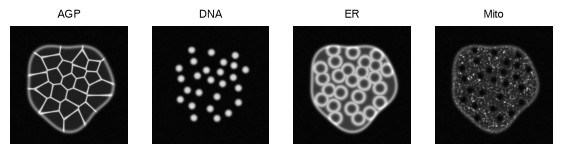

In [7]:
# Quick preview of the four channels
imgs_preview = channel_images()
fig_prev, axes = plt.subplots(1, 4, figsize=(7, 1.9))
for a, (name, img) in zip(axes, imgs_preview.items()):
    a.imshow(img, cmap="gray", origin="lower", vmin=0, vmax=1)
    a.set_title(name, fontsize=8)
    a.axis("off")
plt.show()

## z-stacks and segmentation renderers
`stack` draws a pile of offset slices with content clipped into the front slice.
The `seg_*` functions draw the label maps; `channel_drawer` wraps a channel image for the imaging panel.

In [8]:
def stack(ax, x, y, s, draw_front, n=6, off=0.055, z=10):
    for i in range(n - 1, 0, -1):
        poly(
            ax,
            [
                (x - i * off, y + i * off),
                (x - i * off + s, y + i * off),
                (x - i * off + s, y + i * off + s),
                (x - i * off, y + i * off + s),
            ],
            fc="white",
            ec=GREY,
            lw=0.5,
            z=z,
        )
    clip = poly(
        ax,
        [(x, y), (x + s, y), (x + s, y + s), (x, y + s)],
        fc="black",
        ec=INK,
        lw=0.6,
        z=z + 0.5,
    )
    draw_front(ax, x, y, s, clip, z + 1)


def seg_nuclei(ax, x, y, s, clip, z):
    for pv, c in zip(NUCLEI, LABEL_COLORS):
        p = poly(ax, to_frame(pv, x, y, s), fc=c, ec="none", z=z)
        p.set_clip_path(clip)


def seg_cells(ax, x, y, s, clip, z, cyto=False):
    blob = poly(ax, to_frame(BLOB, x, y, s), fc="none", ec="none", z=z)
    for pv, c in zip(CELLS, LABEL_COLORS):
        p = poly(ax, to_frame(pv, x, y, s), fc=c, ec="black", lw=0.3, z=z)
        p.set_clip_path(blob)
    if cyto:
        for pv in NUCLEI:
            poly(ax, to_frame(pv, x, y, s), fc="black", ec="none", z=z + 0.3)


def seg_organoid(ax, x, y, s, clip, z):
    poly(ax, to_frame(BLOB, x, y, s), fc=SEG_CMAP(0.75), ec="none", z=z)


def channel_drawer(img):
    def draw(ax, x, y, s, clip, z):
        im = ax.imshow(
            img,
            extent=[x, x + s, y, y + s],
            cmap="gray",
            vmin=0,
            vmax=1,
            origin="lower",
            zorder=z,
            interpolation="bilinear",
        )
        im.set_clip_path(clip)

    return draw

## Icons
Outline-style icons for the patient, sample tube, plate, drug and microscope, plus `dissociation`:
a piece of tumor tissue (Voronoi cells clipped to a jagged polygon) broken up into single cells.

In [9]:
def person(ax, cx, cy):
    poly(ax, circle(cx, cy + 0.68, 0.24, 40), fc=LIGHT)
    poly(ax, chamfer(cx - 0.34, cy - 0.38, 0.68, 0.78, 0.18), fc=LIGHT)


def tube(ax, cx, cy, s=1.0, liquid="#b9bec7"):
    P = lambda pts: [(cx + s * dx, cy + s * dy) for dx, dy in pts]
    poly(
        ax,
        P([(-0.16, 0.4), (0.16, 0.4), (0.16, -0.15), (0, -0.52), (-0.16, -0.15)]),
        fc="white",
    )
    poly(
        ax,
        P([(-0.16, -0.02), (0.16, -0.02), (0.16, -0.15), (0, -0.52), (-0.16, -0.15)]),
        fc=liquid,
        ec="none",
        z=3.2,
    )
    poly(
        ax,
        chamfer(cx - 0.21 * s, cy + 0.4 * s, 0.42 * s, 0.14 * s, 0.03 * s),
        fc=LIGHT,
        z=3.3,
    )


def plate(ax, x, y, w, h, highlight=None):
    """96-well plate shaded by dose; optionally rings one well (row, col) and returns its centre and radius."""
    poly(ax, chamfer(x, y, w, h, 0.12), fc="white")
    cmap = LinearSegmentedColormap.from_list("dose", ["#ffffff", SLATE])
    dx, dy = (w - 0.3) / 12, (h - 0.25) / 8
    r = min(dx, dy) * 0.4
    centre = lambda i, j: (x + 0.15 + dx * (j + 0.5), y + 0.12 + dy * (i + 0.5))
    for i in range(8):
        for j in range(12):
            ax.add_patch(
                RegularPolygon(
                    centre(i, j),
                    24,
                    radius=r,
                    fc=cmap(j / 11),
                    ec=INK,
                    lw=0.3,
                    zorder=4,
                )
            )
    if highlight is not None:
        c = centre(*highlight)
        poly(ax, circle(*c, r * 1.6, 32), ec=INK, lw=0.9, z=4.5)
        return c, r * 1.6


def pill(ax, cx, cy, length=0.9, r=0.19, angle=40, z=3):
    t = np.linspace(-np.pi / 2, np.pi / 2, 16)
    half = length / 2 - r
    right = np.c_[half + r * np.cos(t), r * np.sin(t)]
    left = np.c_[-half - r * np.cos(t), r * np.sin(t)][::-1]
    a = np.deg2rad(angle)
    R = np.array([[np.cos(a), -np.sin(a)], [np.sin(a), np.cos(a)]])
    rot = lambda v: v @ R.T + [cx, cy]
    poly(ax, rot(np.vstack([[0, -r], right, [0, r]])), fc=SLATE, z=z)
    poly(ax, rot(np.vstack([[0, r], left, [0, -r]])), fc="white", z=z)


def microscope(ax, x, y):
    poly(ax, chamfer(x, y, 1.2, 0.16, 0.04), fc=LIGHT)  # base
    poly(
        ax,
        [
            (x + 0.88, y + 0.16),
            (x + 1.06, y + 0.16),
            (x + 1.06, y + 1.4),
            (x + 0.73, y + 1.76),
            (x + 0.6, y + 1.63),
            (x + 0.88, y + 1.33),
        ],
        fc=LIGHT,
    )  # arm
    poly(ax, chamfer(x + 0.15, y + 0.6, 0.92, 0.1, 0.02), fc=LIGHT)  # stage
    p0, p1 = np.array([x + 0.42, y + 0.9]), np.array([x + 0.8, y + 1.98])
    u = (p1 - p0) / np.linalg.norm(p1 - p0)
    n = np.array([-u[1], u[0]])
    poly(
        ax,
        [p0 + n * 0.12, p1 + n * 0.12, p1 - n * 0.12, p0 - n * 0.12],
        fc="white",
        z=3.5,
    )
    poly(
        ax,
        [
            p1 + n * 0.16,
            p1 + n * 0.16 + u * 0.13,
            p1 - n * 0.16 + u * 0.13,
            p1 - n * 0.16,
        ],
        fc=GREY,
        z=3.6,
    )  # eyepiece
    poly(
        ax,
        [
            p0 + n * 0.08,
            p0 - n * 0.08,
            p0 - n * 0.05 - u * 0.15,
            p0 + n * 0.05 - u * 0.15,
        ],
        fc=GREY,
        z=3.6,
    )  # objective


def tissue_chunk(ax, cx, cy, r, n_cells, rng_local, jag=0.16):
    """Piece of tissue: Voronoi cells clipped to a jagged outline, one nucleus per cell."""
    k = 13
    t = np.linspace(0, 2 * np.pi, k, endpoint=False)
    rr = r * (1 + jag * rng_local.uniform(-1, 1, k))
    outline = np.c_[cx + rr * np.cos(t), cy + rr * np.sin(t)]
    seeds, min_d = [], r * 1.1 / np.sqrt(n_cells)
    for _ in range(20000):
        if len(seeds) == n_cells:
            break
        p = rng_local.uniform(-0.8 * r, 0.8 * r, 2)
        if np.hypot(*p) < 0.75 * r and all(np.hypot(*(p - q)) > min_d for q in seeds):
            seeds.append(p)
    seeds = np.array(seeds) + [cx, cy]
    clip = poly(ax, outline, fc="none", ec="none", z=4)
    far = np.array(
        [[cx - 50, cy - 50], [cx + 50, cy - 50], [cx + 50, cy + 50], [cx - 50, cy + 50]]
    )
    vor = Voronoi(np.vstack([seeds, far]))
    nr = r * 0.42 / np.sqrt(n_cells)
    for i, sd in enumerate(seeds):
        v = vor.vertices[vor.regions[vor.point_region[i]]]
        c = v.mean(axis=0)
        v = v[np.argsort(np.arctan2(v[:, 1] - c[1], v[:, 0] - c[0]))]
        p = poly(ax, v, fc="#dfe3e8", ec=GREY, lw=0.3, z=4)
        p.set_clip_path(clip)
        poly(ax, circle(*sd, nr, 12), fc=SLATE, ec="none", z=4.2)
    poly(ax, outline, fc="none", ec=INK, lw=0.6, z=4.3)


def single_cell(ax, cx, cy, r=0.06):
    poly(ax, circle(cx, cy, r, 16), fc="#dfe3e8", ec=INK, lw=0.4, z=4)
    poly(ax, circle(cx, cy, r * 0.45, 12), fc=SLATE, ec="none", z=4.2)


def dissociation(ax, x, cy, seed=3):
    """Tumor tissue -> enzymatic/mechanical dissociation -> single-cell suspension."""
    rl = np.random.default_rng(seed)
    tissue_chunk(ax, x + 0.3, cy, 0.3, 10, rl)
    arrow(ax, (x + 0.68, cy), (x + 0.98, cy), w=0.05, hw=0.15, hl=0.11)
    for dx, dy in [
        (0.15, 0.2),
        (0.38, 0.27),
        (0.1, -0.05),
        (0.33, 0.02),
        (0.55, 0.12),
        (0.2, -0.27),
        (0.47, -0.2),
    ]:
        single_cell(ax, x + 1.02 + dx, cy + dy)

## Culture format and assay timeline
Cells are seeded in a ring of Matrigel around the rim of each well, which leaves the centre clear for imaging.

* `well_top` draws one well from above at a given stage of the assay:
  0 = single cells seeded in the Matrigel ring, 1 = organoids forming, 2 = drug added to the medium,
  3 = drug washed out; organoids fixed and stained for Cell Painting.
* `well_side` draws the cross-section (Matrigel in the corners where the wall meets the floor).
* `well_zoom` magnifies the highlighted plate well into a top + side view, joined by a polygon "spotlight".
* `assay_timeline` places the four stages along a timeline arrow. Edit `STAGES` to change days or wording.

In [10]:
RING_IN, RING_OUT = 0.55, 0.9  # Matrigel ring, as a fraction of the well radius

STAGES = [
    ("Day 0", "Seeding in\nMatrigel"),
    ("Days 1–3", "Organoid\nformation"),
    ("Days 4–5", "Drug\ntreatment"),
    ("Day 6", "Cell\nPainting"),
]


def organoid_blob(ax, cx, cy, r, rng_local, z=4.4):
    t = np.linspace(0, 2 * np.pi, 9, endpoint=False) + rng_local.uniform(0, 1)
    rr = r * (1 + rng_local.normal(0, 0.12, len(t)))
    poly(
        ax,
        np.c_[cx + rr * np.cos(t), cy + rr * np.sin(t)],
        fc=SLATE,
        ec="white",
        lw=0.25,
        z=z,
    )


def well_top(ax, cx, cy, r, stage, seed=11):
    rl = np.random.default_rng(seed)
    n = 14
    ang = rl.uniform(0, 2 * np.pi, n)
    rad = rl.uniform(RING_IN + 0.07, RING_OUT - 0.07, n)
    medium = DRUG if stage == 2 else MEDIUM
    poly(ax, circle(cx, cy, r), fc=medium, ec=INK, lw=0.6, z=4)
    poly(ax, circle(cx, cy, r * RING_OUT), fc=MATRIGEL, ec="none", z=4.1)
    poly(ax, circle(cx, cy, r * RING_IN), fc=medium, ec=GREY, lw=0.3, z=4.2)
    size = r * (0.045, 0.075, 0.095, 0.095)[stage]
    for a, d in zip(ang, rad):
        px, py = cx + d * r * np.cos(a), cy + d * r * np.sin(a)
        if stage == 0:
            poly(ax, circle(px, py, size, 10), fc=SLATE, ec="none", z=4.4)
        elif stage == 3:  # stained organoids: dark outline, light core
            poly(ax, circle(px, py, size * 1.05, 12), fc="white", ec=INK, lw=0.5, z=4.4)
            poly(ax, circle(px, py, size * 0.45, 10), fc=SLATE, ec="none", z=4.5)
        else:
            organoid_blob(ax, px, py, size, rl)


def well_side(ax, x, y, w, h, seed=5):
    rl = np.random.default_rng(seed)
    poly(
        ax,
        [(x, y), (x + w, y), (x + w, y + 0.78 * h), (x, y + 0.78 * h)],
        fc=MEDIUM,
        ec="none",
        z=4,
    )
    a, b = 0.3 * w, 0.5 * h
    t = np.linspace(0, np.pi / 2, 20)
    left = np.vstack([[x, y], np.c_[x + a * np.cos(t), y + b * np.sin(t)]])
    right = left.copy()
    right[:, 0] = 2 * x + w - right[:, 0]
    for wedge in (left, right):
        poly(ax, wedge, fc=MATRIGEL, ec=GREY, lw=0.3, z=4.1)
    for side in (0, 1):
        for _ in range(4):
            u, th = rl.uniform(0.2, 0.7), rl.uniform(0.15, 1.4)
            px = x + a * u * np.cos(th)
            px = 2 * x + w - px if side else px
            poly(
                ax,
                circle(px, y + b * u * np.sin(th), 0.018, 10),
                fc=SLATE,
                ec="none",
                z=4.4,
            )
    poly(
        ax,
        [(x, y + h), (x, y), (x + w, y), (x + w, y + h)],
        ec=INK,
        lw=0.9,
        z=4.5,
        closed=False,
    )


def well_zoom(ax, src, src_r, bx, by, bw, bh):
    wx, wy = src
    poly(
        ax,
        [(wx, wy + src_r), (bx, by + bh), (bx, by), (wx, wy - src_r)],
        fc="#dfe2e7",
        ec="none",
        alpha=0.7,
        z=2.6,
    )
    poly(ax, chamfer(bx, by, bw, bh, 0.06), fc="white", ec=INK, lw=0.6, z=3)
    well_top(ax, bx + 0.55, by + 0.8, 0.42, stage=0)
    well_side(ax, bx + bw - 0.92, by + 0.52, 0.74, 0.56)
    text(ax, bx + 0.55, by + 0.17, "top", FS_SMALL, GREY)
    text(ax, bx + bw - 0.55, by + 0.17, "side", FS_SMALL, GREY)


def assay_timeline(ax, x0, x1, y_line, xs, cy, r):
    arrow(ax, (x0, y_line), (x1, y_line), w=0.07, hw=0.24, hl=0.2)
    for k, (cx, (day, desc)) in enumerate(zip(xs, STAGES)):
        well_top(ax, cx, cy, r, stage=k)
        poly(
            ax,
            [
                (cx - 0.012, cy - r),
                (cx + 0.012, cy - r),
                (cx + 0.012, y_line),
                (cx - 0.012, y_line),
            ],
            fc=INK,
            ec="none",
            z=3,
        )
        poly(ax, circle(cx, y_line, 0.065, 20), fc="white", ec=INK, lw=0.7, z=8.5)
        text(ax, cx, cy + r + 0.17, day, weight="bold")
        text(ax, cx, y_line - 0.14, desc, FS_SMALL + 0.5, va="top")
        if k == 2:
            pill(ax, cx + r + 0.28, cy + 0.22, length=0.42, r=0.085, z=4.6)

## Feature extraction
Every profile column is one **compartment × channel × feature type** combination, and the panel is laid out to show that:

* **Rows = compartments.** Each compartment mask (Organoid, Nuclei, Cell, Cytoplasm) is applied to every Cell Painting
  channel (the grid), giving one profile table per compartment.
* **Column blocks = feature types.** Every table has one block of columns per feature type (alphabetical). Each
  feature type's drawing (cut from the feature-type illustration; `FEATURE_TILES` gives each tile's pixel box) sits
  directly above its block, framed in the same `FEATURE_COLORS` colour as the block's top strip, with a pointer into it.
* **Columns within a block = channels.** One column per channel (AGP, DNA, ER, Mito), marked by its `CH_COLORS` strip;
  Colocalization has one column per channel pair (`CHANNEL_PAIRS`; each pair's strip is split in both colours).
  The block, channel and compartment layout follows ZEDprofiler: single-channel features run per compartment × channel,
  Colocalization per compartment × channel pair.
* **Outputs.** The nuclei, cell and cytoplasm tables share the object-ID column and are joined side by side into the
  single-cell profiles; the organoid table follows its own lane to the organoid profiles, kept separate.
* The key in the top-left corner states the rule with the same colour markers: compartment × channel × feature type =
  one profile column.

The ZEDprofiler logo sits at the right end of the panel header.

**How the link is drawn**: three numbered steps read left to right as an equation:
(1) the compartment × channel grid, × (2) every feature type (the drawings, two rows of three),
= (3) one profile column per combination. A small copy of each drawing sits over its column block in (3), framed in the
same feature-type colour, so each drawing maps visibly onto its columns. The key under the grid states the rule:
compartment × channel × feature type = one profile column.

In [11]:
CH_COLORS = {
    "AGP": "#CC00CC",
    "DNA": "#00A6D6",
    "ER": "#00A651",
    "Mito": "#D7191C",
}  # magenta/cyan/green/red
# compartments: dark, saturated hues (Paul Tol), apart from the bright channels and pastel feature types
COMP_COLORS = {
    "Organoid": "#332288",
    "Nuclei": "#882255",
    "Cell": "#DDAA33",
    "Cytoplasm": "#8C510A",
}
# feature types: feature_type_palette from NF1_organoid_profile_analysis/utils/r_plot_themes.r
# (RColorBrewer "Paired"); Neighbors is not in that palette, so it takes Paired[7]
FEATURE_COLORS = {
    "VolumeSizeShape": "#A6CEE3",
    "Colocalization": "#1F78B4",
    "Granularity": "#B2DF8A",
    "Intensity": "#FB9A99",
    "Texture": "#FF7F00",
    "Neighbors": "#FDBF6F",
}
ORG_C, SC_C = COMP_COLORS["Organoid"], COMP_COLORS["Cell"]  # level colours
OUTLINE = "#f0d75a"  # mask outlines drawn over the micrographs
PROFILE_CMAP = LinearSegmentedColormap.from_list(
    "profile", [SLATE, "#f4f4f4", "#b08d3c"]
)
CHANNELS = ["AGP", "DNA", "ER", "Mito"]
# Colocalization is measured per channel pair (example pairs shown; each column is split in the pair's colours)
CHANNEL_PAIRS = [("DNA", "ER"), ("AGP", "Mito"), ("ER", "Mito")]

# where each feature type sits in the feature-type illustration: (x0, x1, y0, y1) in pixels
FEATURE_TILES = {
    "VolumeSizeShape": (0, 955, 0, 743),
    "Colocalization": (955, 1870, 0, 743),
    "Granularity": (1870, 3000, 0, 743),
    "Neighbors": (0, 955, 743, 1500),
    "Intensity": (955, 1870, 743, 1500),
    "Texture": (1870, 3000, 743, 1500),
}
FEATURE_TYPES = sorted(
    FEATURE_TILES
)  # alphabetical; also the order of the column blocks


def seg_cyto(ax, x, y, s, clip, z):
    seg_cells(ax, x, y, s, clip, z, cyto=True)


COMPARTMENTS = [
    ("Organoid", seg_organoid),
    ("Nuclei", seg_nuclei),
    ("Cell", seg_cells),
    ("Cytoplasm", seg_cyto),
]
SC_COMPARTMENTS = ["Nuclei", "Cell", "Cytoplasm"]


def rect(x, y, w, h):
    return [(x, y), (x + w, y), (x + w, y + h), (x, y + h)]


def mask_tile(ax, x, y, s, draw, edge, z=10):
    clip = poly(ax, rect(x, y, s, s), fc="black", ec=edge, lw=0.9, z=z)
    draw(ax, x, y, s, clip, z + 0.5)


def overlay_tile(ax, x, y, s, img, compartment, z=10):
    """Channel image with the compartment's mask outlines on top; frame in the compartment colour."""
    clip = poly(
        ax, rect(x, y, s, s), fc="black", ec=COMP_COLORS[compartment], lw=0.9, z=z
    )
    channel_drawer(img)(ax, x, y, s, clip, z + 0.5)
    blob = poly(ax, to_frame(BLOB, x, y, s), fc="none", ec="none", z=z)
    outlines = {
        "Organoid": [BLOB],
        "Nuclei": NUCLEI,
        "Cell": CELLS,
        "Cytoplasm": CELLS + NUCLEI,
    }[compartment]
    for pv in outlines:
        p = poly(
            ax,
            to_frame(pv, x, y, s),
            fc="none",
            ec=OUTLINE,
            alpha=0.75,
            lw=0.4 if compartment == "Organoid" else 0.18,
            z=z + 1,
        )
        if compartment in ("Cell", "Cytoplasm"):
            p.set_clip_path(blob)


def block_channels(ftype):
    """Columns of one feature-type block: one per channel, or one per channel pair for Colocalization."""
    return CHANNEL_PAIRS if ftype == "Colocalization" else CHANNELS


def channel_strip(ax, x, y, w, h, ch, z=7):
    """Channel marker above a column; a channel pair is split into its two channel colours."""
    if isinstance(ch, tuple):
        poly(ax, rect(x, y, w / 2, h), fc=CH_COLORS[ch[0]], ec="none", z=z)
        poly(ax, rect(x + w / 2, y, w / 2, h), fc=CH_COLORS[ch[1]], ec="none", z=z)
    else:
        poly(ax, rect(x, y, w, h), fc=CH_COLORS[ch], ec="none", z=z)


def column_layout(x0, block_widths, gap, idw):
    """Column positions for a profile table: ID column, then one block per feature type
    (in FEATURE_TYPES order) of the given widths. Returns [(ftype, bx, bw, [(channel, cx, cw), ...]), ...]."""
    x, blocks = x0 + idw + gap, []
    for ftype, bw in zip(FEATURE_TYPES, block_widths):
        chans = block_channels(ftype)
        cw = bw / len(chans)
        blocks.append(
            (ftype, x, bw, [(c, x + i * cw, cw) for i, c in enumerate(chans)])
        )
        x += bw + gap
    return blocks


def n_columns():
    return sum(len(block_channels(f)) for f in FEATURE_TYPES)


def draw_profile(ax, x0, y, h, vals, blocks, id_colors, edge, idw, strip=0.075, z=6):
    """Profile table: rows = objects (ID column on the left), columns grouped into feature-type blocks.
    Above every block: its feature-type strip; above every column: its channel (or channel-pair) strip."""
    n_rows = vals.shape[0]
    rh = h / n_rows
    for i, c in enumerate(id_colors):  # object-ID column
        poly(ax, rect(x0, y + h - (i + 1) * rh, idw, rh), fc=c, ec="white", lw=0.3, z=z)
    poly(ax, rect(x0, y, idw, h), ec=INK, lw=0.4, z=z + 0.5)
    j = 0
    for ftype, bx, bw, cols in blocks:
        poly(
            ax,
            rect(bx, y + h + 0.03 + strip + 0.02, bw, strip),
            fc=FEATURE_COLORS[ftype],
            ec="none",
            z=z,
        )
        for ch, cx, cw in cols:
            channel_strip(ax, cx + 0.01, y + h + 0.03, cw - 0.02, strip, ch, z=z)
            for i in range(n_rows):
                c = PROFILE_CMAP(np.clip((vals[i, j] + 2) / 4, 0, 1))
                poly(
                    ax,
                    rect(cx, y + h - (i + 1) * rh, cw, rh),
                    fc=c,
                    ec="white",
                    lw=0.2,
                    z=z,
                )
            j += 1
        poly(ax, rect(bx, y, bw, h), ec=edge, lw=0.9, z=z + 0.5)


def table_values(rl, n_rows, n_cols):
    return rl.normal(0, 0.6, (n_rows, n_cols)) + rl.normal(0, 0.9, n_cols)


def formula_key(ax, x, y_top, dy=0.33):
    """compartment x channel x feature type = one profile column, drawn with the figure's own markers."""
    rows = [
        ("", "compartment", [COMP_COLORS[c] for c in COMP_COLORS]),
        ("×", "channel", [CH_COLORS[c] for c in CHANNELS]),
        ("×", "feature type", [FEATURE_COLORS[f] for f in FEATURE_TYPES]),
    ]
    for k, (op, label, colors) in enumerate(rows):
        y = y_top - k * dy
        text(ax, x, y, op, FS_LABEL + 1, weight="bold")
        sw = 0.62 / len(colors)
        for i, c in enumerate(colors):
            poly(ax, rect(x + 0.18 + i * sw, y - 0.08, sw, 0.16), fc=c, ec="none", z=6)
        text(ax, x + 0.9, y, label, FS_SMALL, ha="left")
    y = y_top - 3 * dy - 0.05
    text(ax, x, y, "=", FS_LABEL + 1, weight="bold")
    for i in range(4):  # one column of values
        c = PROFILE_CMAP(0.2 + 0.2 * i)
        poly(
            ax,
            rect(x + 0.4, y + 0.2 - (i + 1) * 0.1, 0.14, 0.1),
            fc=c,
            ec="white",
            lw=0.2,
            z=6,
        )
    poly(ax, rect(x + 0.4, y - 0.2, 0.14, 0.4), ec=INK, lw=0.5, z=6.5)
    text(ax, x + 0.9, y, "one profile column", FS_SMALL, ha="left", weight="bold")


# ---------------------------------------------------------------------------------------------
# Shared pieces of the feature-extraction panel
# ---------------------------------------------------------------------------------------------
ROW_PITCH, TH = 0.74, 0.5  # table row spacing and height
TILE_S, TILE_PITCH, GRID_X = 0.5, 0.6, 2.05  # compartment x channel grid
IDW, BLOCK_GAP, X_END = 0.22, 0.14, 18.85  # tables
ORG_IDS = [
    LinearSegmentedColormap.from_list("o", ["#eeeeee", "#555555"])(v)
    for v in (0.2, 0.55, 0.9)
]
SC_IDS = [
    LinearSegmentedColormap.from_list("s", ["#f2f2f2", "#4d4d4d"])(v)
    for v in np.linspace(0.05, 1, 6)
]
SMALL_ARROW = dict(w=0.07, hw=0.2, hl=0.15)


def drawing_aspects():
    return [
        (FEATURE_TILES[f][1] - FEATURE_TILES[f][0])
        / (FEATURE_TILES[f][3] - FEATURE_TILES[f][2])
        for f in FEATURE_TYPES
    ]


def draw_tile(ax, illustration, ftype, x, y_top, w, h):
    """One feature-type drawing, framed in its feature-type colour."""
    px0, px1, py0, py1 = FEATURE_TILES[ftype]
    ax.imshow(
        illustration[py0:py1, px0:px1],
        extent=[x, x + w, y_top - h, y_top],
        zorder=5,
        interpolation="lanczos",
    )
    poly(
        ax,
        chamfer(x - 0.03, y_top - h - 0.03, w + 0.06, h + 0.06, 0.08),
        ec=FEATURE_COLORS[ftype],
        lw=2.0,
        z=6,
    )


def blocks_by_columns(tx, x_end=None):
    """Column blocks whose widths follow their number of columns, filling tx..x_end."""
    x_end = X_END if x_end is None else x_end
    cw = (x_end - tx - IDW - BLOCK_GAP * len(FEATURE_TYPES)) / n_columns()
    return column_layout(
        tx, [cw * len(block_channels(f)) for f in FEATURE_TYPES], BLOCK_GAP, IDW
    )


def compartment_grid(ax, imgs, row_c, to_x=None):
    """Compartment (rows) x channel (columns) grid; optional arrows from each row to to_x.
    Returns the grid's right edge."""
    s, pitch, gx = TILE_S, TILE_PITCH, GRID_X
    for j, ch in enumerate(CHANNELS, start=1):
        cx_ = gx + j * pitch
        text(
            ax,
            cx_ + s / 2,
            row_c[0] + s / 2 + 0.22,
            ch,
            FS_SMALL - 1.5,
            CH_COLORS[ch],
            "bold",
        )
        poly(
            ax,
            rect(cx_, row_c[0] + s / 2 + 0.05, s, 0.05),
            fc=CH_COLORS[ch],
            ec="none",
            z=5,
        )
    right = gx + 4 * pitch + s
    for (name, draw), yc in zip(COMPARTMENTS, row_c):
        col = COMP_COLORS[name]
        text(ax, gx - 0.08, yc, name, FS_LABEL - 0.5, col, "bold", ha="right")
        mask_tile(ax, gx, yc - s / 2, s, draw, col)
        for j, ch in enumerate(CHANNELS, start=1):
            overlay_tile(ax, gx + j * pitch, yc - s / 2, s, imgs[ch], name)
        if to_x is not None:
            arrow(ax, (right + 0.05, yc), (to_x - 0.04, yc), color=col, **SMALL_ARROW)
    return right


def compartment_tables(ax, tx, blocks, row_c, rl):
    """One profile table per compartment, aligned with the grid rows."""
    tables = {}
    for (name, _), yc in zip(COMPARTMENTS, row_c):
        ids = ORG_IDS if name == "Organoid" else SC_IDS
        vals = table_values(rl, len(ids), n_columns())
        tables[name] = vals
        draw_profile(ax, tx, yc - TH / 2, TH, vals, blocks, ids, COMP_COLORS[name], IDW)
    return tables


def profile_outputs(ax, x_end, row_c, tables):
    """Nuclei | cell | cytoplasm joined into single-cell profiles; organoid profiles in their own lane.
    Returns the lowest y drawn."""
    sc_lane, org_lane = x_end + 0.22, x_end + 0.42
    y_m, y_o = row_c[3] - 1.05, row_c[3] - 1.8
    for name, yc in zip(SC_COMPARTMENTS, row_c[1:]):
        bar(ax, (x_end + 0.02, yc), (sc_lane, yc), w=0.05, color=COMP_COLORS[name])
    bar(ax, (sc_lane, row_c[1]), (sc_lane, y_m), w=0.05, color=SC_C)
    bar(ax, (x_end + 0.02, row_c[0]), (org_lane, row_c[0]), w=0.05, color=ORG_C)
    bar(ax, (org_lane, row_c[0]), (org_lane, y_o), w=0.05, color=ORG_C)

    mcw, mgap, sgap, oh = 0.075, 0.05, 0.22, 0.42  # small output tables
    small_widths = [len(block_channels(f)) * mcw for f in FEATURE_TYPES]
    sec_w = sum(small_widths) + mgap * len(FEATURE_TYPES)
    m_end = sc_lane - 0.3
    m_x0 = m_end - (IDW + 3 * sec_w + 2 * sgap)
    arrow(ax, (sc_lane, y_m), (m_end + 0.03, y_m), color=SC_C, **SMALL_ARROW)
    x = m_x0 + IDW
    for k, name in enumerate(SC_COMPARTMENTS):
        sec_blocks = column_layout(x - IDW - mgap, small_widths, mgap, IDW)
        if k == 0:
            draw_profile(
                ax,
                m_x0,
                y_m - oh / 2,
                oh,
                tables[name],
                sec_blocks,
                SC_IDS,
                COMP_COLORS[name],
                IDW,
                strip=0.06,
            )
        else:
            draw_profile(
                ax,
                x - IDW,
                y_m - oh / 2,
                oh,
                tables[name],
                sec_blocks,
                SC_IDS,
                COMP_COLORS[name],
                0,
                strip=0.06,
            )
        band_y = y_m + oh / 2 + 0.2
        poly(ax, rect(x, band_y, sec_w, 0.05), fc=COMP_COLORS[name], ec="none", z=6)
        text(
            ax, x + sec_w / 2, band_y + 0.17, name, FS_SMALL, COMP_COLORS[name], "bold"
        )
        x += sec_w + sgap
    text(
        ax,
        m_x0 - 0.15,
        y_m,
        "Single-cell profiles\n(joined on object ID)",
        FS_LABEL,
        SC_C,
        "bold",
        ha="right",
    )

    o_end = org_lane - 0.3
    o_x0 = o_end - (IDW + sec_w)
    arrow(ax, (org_lane, y_o), (o_end + 0.03, y_o), color=ORG_C, **SMALL_ARROW)
    draw_profile(
        ax,
        o_x0,
        y_o - oh / 2,
        oh,
        tables["Organoid"],
        column_layout(o_x0, small_widths, mgap, IDW),
        ORG_IDS,
        ORG_C,
        IDW,
        strip=0.06,
    )
    text(
        ax,
        o_x0 - 0.15,
        y_o,
        "Organoid profiles (kept separate)",
        FS_LABEL,
        ORG_C,
        "bold",
        ha="right",
    )
    return y_o - oh / 2


def profile_outputs_line(ax, tables, y_top, x_left=0.6):
    """One line along the bottom of the panel: single-cell profiles on the left (nuclei | cell | cytoplasm joined on
    object ID), organoid profiles on the right (kept separate). Lanes run from the right edge of the step-3 tables.
    Returns the lowest y drawn."""
    mcw, mgap, sgap, oh = 0.068, 0.045, 0.2, 0.42
    small_widths = [len(block_channels(f)) * mcw for f in FEATURE_TYPES]
    sec_w = sum(small_widths) + mgap * len(FEATURE_TYPES)
    y_ch = y_top - 0.1  # routing channel for the single-cell lane
    y_out = y_top - 0.82  # centre of the output tables (band labels above)
    sc_lane, org_lane = X_END + 0.22, X_END + 0.42

    # single-cell profiles, left
    m_x0 = x_left
    x = m_x0 + IDW
    for k, name in enumerate(SC_COMPARTMENTS):
        sec_blocks = column_layout(x - IDW - mgap, small_widths, mgap, IDW)
        draw_profile(
            ax,
            x - IDW if k else m_x0,
            y_out - oh / 2,
            oh,
            tables[name],
            sec_blocks,
            SC_IDS,
            COMP_COLORS[name],
            0 if k else IDW,
            strip=0.06,
        )
        band_y = y_out + oh / 2 + 0.2
        poly(ax, rect(x, band_y, sec_w, 0.05), fc=COMP_COLORS[name], ec="none", z=6)
        text(
            ax, x + sec_w / 2, band_y + 0.17, name, FS_SMALL, COMP_COLORS[name], "bold"
        )
        x += sec_w + sgap
    m_end = x - sgap
    drop = m_end + 0.18
    bar(ax, (sc_lane, row_ends["sc_top"]), (sc_lane, y_ch), w=0.05, color=SC_C)
    bar(ax, (sc_lane, y_ch), (drop, y_ch), w=0.05, color=SC_C)
    bar(ax, (drop, y_ch), (drop, y_out), w=0.05, color=SC_C)
    arrow(ax, (drop, y_out), (m_end + 0.03, y_out), color=SC_C, **SMALL_ARROW)
    text(
        ax,
        drop + 0.2,
        y_out,
        "Single-cell profiles\n(joined on object ID)",
        FS_LABEL,
        SC_C,
        "bold",
        ha="left",
    )

    # organoid profiles, right
    o_w = IDW + sec_w
    o_x0 = X_END + 0.1 - o_w
    bar(ax, (org_lane, row_ends["org"]), (org_lane, y_out), w=0.05, color=ORG_C)
    arrow(ax, (org_lane, y_out), (o_x0 + o_w + 0.03, y_out), color=ORG_C, **SMALL_ARROW)
    draw_profile(
        ax,
        o_x0,
        y_out - oh / 2,
        oh,
        tables["Organoid"],
        column_layout(o_x0, small_widths, mgap, IDW),
        ORG_IDS,
        ORG_C,
        IDW,
        strip=0.06,
    )
    text(
        ax,
        o_x0 - 0.15,
        y_out,
        "Organoid profiles\n(kept separate)",
        FS_LABEL,
        ORG_C,
        "bold",
        ha="right",
    )
    return y_out - oh / 2


row_ends = {}  # y where each output lane starts (filled by fe_steps)


def table_stubs(ax, row_c):
    """Short coloured stubs from the right edge of each step-3 table into the two output lanes."""
    sc_lane, org_lane = X_END + 0.22, X_END + 0.42
    for name, yc in zip(SC_COMPARTMENTS, row_c[1:]):
        bar(ax, (X_END + 0.02, yc), (sc_lane, yc), w=0.05, color=COMP_COLORS[name])
    bar(ax, (X_END + 0.02, row_c[0]), (org_lane, row_c[0]), w=0.05, color=ORG_C)
    row_ends["sc_top"], row_ends["org"] = row_c[1], row_c[0]


def rows_from(t_top0, pitch=ROW_PITCH):
    return [t_top0 - TH / 2 - k * pitch for k in range(4)]


# ---------------------------------------------------------------------------------------------
# Panel body, in three numbered steps:
#   (1) compartment x channel grid  x  (2) every feature type (drawings)  =  (3) one column per combination
# A small copy of each drawing sits over its column block, so (2) maps visibly onto (3).
# ---------------------------------------------------------------------------------------------
def step_badge(ax, x, y, n, label):
    poly(ax, circle(x, y, 0.16, 32), fc=INK, ec="none", z=8)
    text(ax, x, y - 0.005, str(n), FS_SMALL, "white", "bold")
    text(ax, x + 0.26, y, label, FS_LABEL, ha="left", weight="bold")


def block_thumbnails(ax, illustration, blocks, y_bottom, max_h=0.62):
    """A small copy of each feature-type drawing over its column block, framed in the feature-type colour."""
    for ftype, bx, bw, _ in blocks:
        px0, px1, py0, py1 = FEATURE_TILES[ftype]
        a = (px1 - px0) / (py1 - py0)
        w = min(bw, max_h * a)
        h = w / a
        x = bx + (bw - w) / 2
        ax.imshow(
            illustration[py0:py1, px0:px1],
            extent=[x, x + w, y_bottom, y_bottom + h],
            zorder=5,
            interpolation="lanczos",
        )
        poly(
            ax,
            rect(x - 0.02, y_bottom - 0.02, w + 0.04, h + 0.04),
            ec=FEATURE_COLORS[ftype],
            lw=1.2,
            z=6,
        )
        poly(
            ax,
            [
                (bx + bw / 2 - 0.07, y_bottom - 0.03),
                (bx + bw / 2 + 0.07, y_bottom - 0.03),
                (bx + bw / 2, y_bottom - 0.12),
            ],
            fc=FEATURE_COLORS[ftype],
            ec="none",
            z=6,
        )


def fe_steps(ax, imgs, bt, illustration, rl):
    dh, dgap, rgap = (
        2.15,
        0.14,
        0.14,
    )  # drawing height, gap between drawings, gap between rows
    yb = bt - 0.22  # step labels
    d_top = bt - 0.5
    span = 2 * dh + rgap  # height of the two drawing rows
    d_bottom = d_top - span
    # (1) compact compartment x channel grid, top-left; the key sits right under it
    grid_c = [d_top - 0.62 - k * (TILE_S + 0.1) for k in range(4)]
    right = compartment_grid(ax, imgs, grid_c)
    formula_key(ax, 0.75, grid_c[3] - TILE_S / 2 - 0.42)
    # (2) drawings, two rows of three
    dx0 = right + 0.6
    aspects = dict(zip(FEATURE_TYPES, drawing_aspects()))
    row_w = []
    for r, row in enumerate([FEATURE_TYPES[:3], FEATURE_TYPES[3:]]):
        x = dx0
        for n in row:
            w = dh * aspects[n]
            draw_tile(ax, illustration, n, x, d_top - r * (dh + rgap), w, dh)
            x += w + dgap
        row_w.append(x - dgap)
    dx1 = max(row_w)
    # (3) one table per compartment; thumbnails tie each block to its drawing
    thumb = 0.62
    row_c = rows_from(d_top - thumb - 0.15, pitch=(span - thumb - 0.15 - TH) / 3)
    tx = dx1 + 0.45
    blocks = blocks_by_columns(tx)
    block_thumbnails(
        ax, illustration, blocks, row_c[0] + TH / 2 + 0.3, max_h=thumb - 0.1
    )
    tables = compartment_tables(ax, tx, blocks, row_c, rl)
    ymid = d_top - span / 2
    text(
        ax,
        (right + dx0) / 2,
        (grid_c[0] + grid_c[3]) / 2,
        "×",
        FS_TITLE + 8,
        weight="bold",
    )
    text(ax, (dx1 + tx) / 2, ymid, "=", FS_TITLE + 8, weight="bold")
    step_badge(ax, 0.75, yb, 1, "Compartment × channel")
    step_badge(ax, dx0 + 0.1, yb, 2, "× every feature type")
    step_badge(ax, tx, yb, 3, "= profile columns")
    # outputs: one line along the bottom
    table_stubs(ax, row_c)
    return profile_outputs_line(ax, tables, d_bottom - 0.12)


def feature_extraction(ax, imgs, top, illustration, logo_path):
    """Feature-extraction panel. Returns the y of the panel's bottom edge."""
    head = 1.0  # taller header bar so the ZEDprofiler logo can be large
    bt = top - head - 0.15  # top of the panel body
    lowest = fe_steps(ax, imgs, bt, illustration, np.random.default_rng(4))
    bottom = lowest - 0.2
    panel(ax, 0.3, bottom, 19.4, bt - bottom, head, "3D feature extraction", letter="D")
    place_logo(ax, logo_path, 19.6, top - head / 2, head * 0.9, anchor="right")
    return bottom

## Image-based profiling
Merged from `profiling_workflow.ipynb`: the pipeline after feature extraction, one card per step with a small schematic
of what the step does to the data (all simulated). Each card shows its tool's logo in the top-left corner.

| Step | Tool | Schematic |
|---|---|---|
| Quality control | coSMicQC | outlier single cells (scatter) and size-outlier organoids (top row) are dropped |
| Normalize | pycytominer | features on different scales → z-scored |
| Feature selection | pycytominer | low-variance, correlated and NA columns removed |
| Aggregate (per well) | pycytominer | single cells → one median profile per well |
| Consensus (per drug) | pycytominer | replicate wells → one profile per drug |

Heatmaps use `PROFILE_CMAP`, the same colours as the feature tables above. Edit `PROFILING_STEPS` to rename steps.

In [12]:
PROF_RNG = np.random.default_rng(7)
KEEP_C, DROP_C = SLATE, "#D7263D"
DRUG_COLORS = {"A": "#3F468C", "B": "#D9622B"}
DIST_COLORS = [
    "#1F78B4",
    "#FF7F00",
    "#33A02C",
]  # three example features (Paired, dark shades)
N_FEAT = 8
FS_TINY = 6.5


def inset(ax, x, y, w, h):
    a = ax.inset_axes([x, y, w, h], transform=ax.transData)
    a.set_zorder(6)
    return a


def heatmap(a, data, ylabels=None, ylabel_colors=None, fs=FS_TINY, labels_right=False):
    cmap = PROFILE_CMAP.copy()
    cmap.set_bad("white")
    a.imshow(
        data, cmap=cmap, vmin=-2.5, vmax=2.5, aspect="auto", interpolation="nearest"
    )
    a.set_xticks([])
    if ylabels is None:
        a.set_yticks([])
    else:
        a.set_yticks(range(len(ylabels)))
        a.set_yticklabels(ylabels, fontsize=fs)
        a.tick_params(axis="y", length=0, pad=1)
        if labels_right:
            a.yaxis.tick_right()
        if ylabel_colors:
            for t, c in zip(a.get_yticklabels(), ylabel_colors):
                t.set_color(c)
                t.set_fontweight("bold")
    for s in a.spines.values():
        s.set_linewidth(0.5)


def tiny_title(a, s):
    a.set_title(s, fontsize=FS_TINY + 0.5, pad=1.5, color="#333333")


def mini_arrow(ax, x0, x1, y, label=None, above=False):
    arrow(ax, (x0, y), (x1, y), w=0.03, hw=0.11, hl=0.08, z=9)
    if label:  # label beside the arrow, clear of the schematics on either side
        if above:
            text(ax, (x0 + x1) / 2, y + 0.08, label, FS_TINY, va="bottom")
        else:
            text(ax, (x0 + x1) / 2, y - 0.08, label, FS_TINY, va="top")


def draw_qc(ax, rect):
    """Organoids: size outliers dropped (top row). Single cells: outliers outside the gate dropped."""
    x, y, w, h = rect
    band = h * 0.24
    org_y = y + h - band / 2
    sizes = [0.52, 0.58, 0.5, 1.1, 0.56, 0.6, 0.38, 0.54]
    dropped = [False, False, False, True, False, False, True, False]
    for ox, s, d in zip(
        np.linspace(x + 0.25, x + w - 0.25, len(sizes)), sizes, dropped
    ):
        r = s * band * 0.42
        poly(
            ax,
            circle(ox, org_y, r, 28),
            fc=DROP_C if d else "#E7E9ED",
            ec=DROP_C if d else "#777777",
            lw=0.5,
            z=6,
        )
        if d:
            ax.plot(
                ox,
                org_y,
                marker="x",
                color="white",
                ms=max(2.0, r * 30),
                mew=0.8,
                zorder=7,
            )
    a = inset(ax, x + 0.36, y + 0.2, w - 0.41, h - band - 0.3)
    n = 260
    area = PROF_RNG.normal(0, 1, n)
    inten = 0.5 * area + PROF_RNG.normal(0, 0.85, n)
    area = np.concatenate(
        [area, PROF_RNG.normal(4.2, 0.4, 7), PROF_RNG.normal(-3.6, 0.3, 6)]
    )
    inten = np.concatenate(
        [inten, PROF_RNG.normal(3.6, 0.5, 7), PROF_RNG.normal(-3.3, 0.4, 6)]
    )
    lo, hi = -2.6, 2.6
    bad = (area < lo) | (area > hi) | (inten < lo) | (inten > hi)
    a.scatter(area[~bad], inten[~bad], s=1.2, c=KEEP_C, alpha=0.6, lw=0)
    a.scatter(area[bad], inten[bad], s=6, c=DROP_C, marker="x", lw=0.6)
    a.add_patch(
        plt.Rectangle(
            (lo, lo), hi - lo, hi - lo, fill=False, ls="--", lw=0.5, ec="#333333"
        )
    )
    a.text(
        hi - 0.1,
        lo + 0.15,
        "keep",
        fontsize=FS_TINY,
        ha="right",
        va="bottom",
        color=KEEP_C,
        fontweight="bold",
    )
    a.text(
        5.2,
        1.6,
        "drop",
        fontsize=FS_TINY,
        ha="right",
        va="top",
        color=DROP_C,
        fontweight="bold",
    )
    a.set_xlim(-5, 5.4)
    a.set_ylim(-5, 5.2)
    a.set_xticks([])
    a.set_yticks([])
    a.set_xlabel("nucleus area", fontsize=FS_TINY, labelpad=0.5)
    a.set_ylabel("DNA intensity", fontsize=FS_TINY, labelpad=0.5)
    for s in a.spines.values():
        s.set_linewidth(0.5)


def draw_normalize(ax, rect):
    """Features on different scales -> centred and scaled relative to controls."""
    x, y, w, h = rect
    left = inset(ax, x, y + 0.1, w * 0.4, h - 0.35)
    right = inset(ax, x + w * 0.6, y + 0.1, w * 0.4, h - 0.35)
    xs = np.linspace(-1, 18, 400)
    for (mu, sd), c in zip([(2.0, 0.7), (6.0, 1.5), (11.0, 2.4)], DIST_COLORS):
        pdf = np.exp(-0.5 * ((xs - mu) / sd) ** 2) / sd
        left.fill_between(xs, pdf, color=c, alpha=0.35, lw=0)
        left.plot(xs, pdf, color=c, lw=0.7)
    tiny_title(left, "raw")
    zs = np.linspace(-4, 4, 300)
    for i, c in enumerate(DIST_COLORS):
        sd = 1 + 0.06 * (i - 1)
        pdf = np.exp(-0.5 * (zs / sd) ** 2) / sd
        right.fill_between(zs, pdf, color=c, alpha=0.25, lw=0)
        right.plot(zs, pdf, color=c, lw=0.7)
    right.axvline(0, color="#333333", lw=0.5, ls=":")
    tiny_title(right, "normalized")
    for a in (left, right):
        a.set_xticks([])
        a.set_yticks([])
        for s in ("top", "right", "left"):
            a.spines[s].set_visible(False)
        a.spines["bottom"].set_linewidth(0.5)
    mini_arrow(ax, x + w * 0.41, x + w * 0.59, y + h * 0.62, "(x − μ) / σ", above=True)


def draw_feature_select(ax, rect):
    """Feature matrix with low-variance, correlated and NA columns removed."""
    x, y, w, h = rect
    n_rows, n_cols = 7, 12
    data = PROF_RNG.normal(0, 1.1, (n_rows, n_cols))
    var_col, corr_pair, na_col = 2, (5, 6), 9
    data[:, var_col] = 0.15 + PROF_RNG.normal(0, 0.03, n_rows)
    data[:, corr_pair[1]] = data[:, corr_pair[0]] + PROF_RNG.normal(0, 0.12, n_rows)
    data[PROF_RNG.choice(n_rows, 4, replace=False), na_col] = np.nan
    dropped = {var_col: "var", corr_pair[1]: "corr", na_col: "NA"}
    lw_frac = 0.5
    left = inset(ax, x, y + 0.05, w * lw_frac, h - 0.42)
    heatmap(left, data)
    for r, c in zip(*np.where(np.isnan(data))):
        left.add_patch(
            plt.Rectangle(
                (c - 0.5, r - 0.5), 1, 1, fill=False, hatch="////", ec="#AAAAAA", lw=0
            )
        )
    for c, why in dropped.items():
        left.axvspan(c - 0.5, c + 0.5, color="white", alpha=0.55, lw=0)
        left.plot(c, -0.95, marker="x", color=DROP_C, ms=3, mew=0.9, clip_on=False)
        left.text(
            c,
            -1.45,
            why,
            ha="center",
            va="bottom",
            fontsize=FS_TINY - 1,
            color=DROP_C,
            clip_on=False,
        )
    left.set_ylim(n_rows - 0.5, -0.5)
    keep = [c for c in range(n_cols) if c not in dropped]
    rw = w * lw_frac * len(keep) / n_cols
    right = inset(ax, x + w - rw, y + 0.05, rw, h - 0.42)
    heatmap(right, data[:, keep])
    tiny_title(right, f"{len(keep)} of {n_cols} kept")
    mini_arrow(ax, x + w * lw_frac + 0.08, x + w - rw - 0.08, y + h * 0.4)


def draw_well_median(ax, rect):
    """Many single cells per well -> one median profile per well."""
    x, y, w, h = rect
    wells = ["A01", "A02", "A03"]
    well_means = PROF_RNG.normal(0, 1.3, (len(wells), N_FEAT))
    left = inset(ax, x, y, w * 0.48, h - 0.3)
    left.set_xlim(-0.2, 7.0)
    left.set_ylim(-1.75, 1.25)
    left.set_aspect("equal", adjustable="box")
    left.axis("off")
    medians = []
    for i, name in enumerate(wells):
        cx = 1.1 + i * 2.4
        cells = well_means[i] + PROF_RNG.normal(0, 0.9, (22, N_FEAT))
        medians.append(np.median(cells, axis=0))
        left.add_patch(plt.Circle((cx, 0), 1.0, fc="#F4F4F4", ec="#555555", lw=0.6))
        r = 0.8 * np.sqrt(PROF_RNG.uniform(0, 1, 22))
        t = PROF_RNG.uniform(0, 2 * np.pi, 22)
        left.scatter(
            cx + r * np.cos(t),
            r * np.sin(t),
            s=2,
            c=cells[:, 0],
            cmap=PROFILE_CMAP,
            vmin=-2.5,
            vmax=2.5,
            lw=0.15,
            ec="#333333",
        )
        left.text(cx, -1.25, name, ha="center", va="top", fontsize=FS_TINY - 1)
    tiny_title(left, "cells per well")
    right = inset(ax, x + w * 0.68, y + 0.25, w * 0.17, h - 0.65)
    heatmap(right, np.array(medians), ylabels=wells, labels_right=True)
    tiny_title(right, "well medians")
    mini_arrow(ax, x + w * 0.5, x + w * 0.65, y + h * 0.4)


def draw_consensus(ax, rect):
    """Replicate well profiles of the same drug -> one consensus profile."""
    x, y, w, h = rect
    n_rep = 3
    rows, labels, label_colors, consensus = [], [], [], []
    for d, col in DRUG_COLORS.items():
        reps = PROF_RNG.normal(0, 1.4, N_FEAT) + PROF_RNG.normal(
            0, 0.55, (n_rep, N_FEAT)
        )
        rows.append(reps)
        consensus.append(np.median(reps, axis=0))
        labels += [f"{d}·rep{i + 1}" for i in range(n_rep)]
        label_colors += [col] * n_rep
    left = inset(ax, x + 0.72, y + 0.05, w * 0.22, h - 0.42)
    heatmap(
        left,
        np.vstack(rows),
        ylabels=labels,
        ylabel_colors=label_colors,
        fs=FS_TINY - 0.5,
    )
    left.axhline(n_rep - 0.5, color="black", lw=0.8)
    tiny_title(left, "replicates")
    right = inset(ax, x + w * 0.58, y + 0.3, w * 0.13, h - 0.9)
    heatmap(
        right,
        np.array(consensus),
        ylabels=[f"drug {d}" for d in DRUG_COLORS],
        ylabel_colors=list(DRUG_COLORS.values()),
        labels_right=True,
    )
    tiny_title(right, "medians")
    mini_arrow(ax, x + w * 0.45, x + w * 0.56, y + h * 0.4)


# (title, short note or None, tool, schematic)
PROFILING_STEPS = [
    ("Quality control", None, "coSMicQC", draw_qc),
    ("Normalize", None, "pycytominer", draw_normalize),
    ("Feature\nselection", None, "pycytominer", draw_feature_select),
    ("Aggregate", "(per well)", "pycytominer", draw_well_median),
    ("Consensus", "(per drug)", "pycytominer", draw_consensus),
]


def image_based_profiling(ax, top, logos):
    """Profiling row: one card per step, left to right, joined by arrows; each card shows its tool's logo.
    logos maps tool name -> logo path."""
    BODY = 3.0
    panel(
        ax,
        0.3,
        top - HEAD_H - 0.15 - BODY,
        19.4,
        BODY,
        HEAD_H,
        "Image-based profiling",
        letter="E",
    )
    bt = top - HEAD_H - 0.15
    cw, gap = 3.5, 0.32
    y0, ch = bt - BODY + 0.15, BODY - 0.3
    for i, (title, note, tool, draw) in enumerate(PROFILING_STEPS):
        x0 = 0.6 + i * (cw + gap)
        poly(ax, chamfer(x0, y0, cw, ch, 0.08), fc="white", ec=INK, lw=0.6, z=4)
        place_logo(ax, logos[tool], x0 + 0.08, y0 + ch - 0.45, 0.8, anchor="left")
        tx_ = x0 + 0.92 + (cw - 0.92) / 2
        if note:  # wrap: title, then the note on its own line
            text(ax, tx_, y0 + ch - 0.28, title, FS_LABEL - 0.5, weight="bold")
            text(ax, tx_, y0 + ch - 0.6, note, FS_SMALL - 0.5, GREY)
        else:
            text(ax, tx_, y0 + ch - 0.45, title, FS_LABEL - 0.5, weight="bold")
        draw(ax, (x0 + 0.15, y0 + 0.12, cw - 0.3, ch - 1.0))
        if i < len(PROFILING_STEPS) - 1:
            arrow(
                ax,
                (x0 + cw + 0.05, y0 + ch / 2),
                (x0 + cw + gap - 0.05, y0 + ch / 2),
                w=0.08,
                hw=0.24,
                hl=0.18,
            )
    return top - HEAD_H - 0.15 - BODY

## Panel frame
A light-grey header bar above a dashed body.
`place_logo` puts a software logo (raster) at a given height.
Each panel carries a bold letter (A–E) at the left end of its header, for the figure caption.

In [13]:
def panel(ax, x, y_body, w, h_body, h_head, title, letter=None):
    """Dashed body with a light-grey header bar; `letter` (A, B, ...) sits at the header's left end
    so the panel can be referenced in the figure caption."""
    poly(ax, chamfer(x, y_body, w, h_body, 0.12), ec=GREY, lw=0.6, ls=(0, (3, 2)), z=1)
    hy = y_body + h_body + 0.15
    poly(ax, chamfer(x, hy, w, h_head, 0.12), fc=LIGHT, ec=INK, lw=0.6, z=2)
    text(ax, x + w / 2, hy + h_head / 2, title, FS_TITLE, weight="bold")
    if letter:
        text(
            ax,
            x + 0.25,
            hy + h_head / 2,
            letter,
            FS_TITLE + 3,
            weight="bold",
            ha="left",
        )


def place_logo(ax, path, x, y, h, anchor="center", z=8):
    """Raster logo of height h centred vertically on y; anchor sets whether x is its left, centre or right."""
    img = plt.imread(path)
    w = h * img.shape[1] / img.shape[0]
    x0 = {"left": x, "center": x - w / 2, "right": x - w}[anchor]
    ax.imshow(
        img,
        extent=[x0, x0 + w, y - h / 2, y + h / 2],
        zorder=z,
        interpolation="lanczos",
    )

## Build the figure
All positions are in drawing units. Top row: patient-derived organoids → culture & drug treatment.
Middle row: imaging → segmentation. Then, below y = 0 (down to `Y_MIN`): feature extraction, then image-based profiling.

In [14]:
def build_figure():
    fig = plt.figure(figsize=(FIG_W_IN, FIG_W_IN * (H - Y_MIN) / W), facecolor="white")
    ax = fig.add_axes([0, 0, 1, 1])
    HEAD = HEAD_H
    small = dict(w=0.08, hw=0.24, hl=0.18)
    TOP_Y, TOP_H = 4.1, 2.75  # top-row panel body
    YC = 5.65  # icon centre line, top row
    LY, LKW = 4.8, dict(size=FS_SMALL, va="top")

    # ---- Patient-derived organoids ----
    panel(
        ax,
        0.3,
        TOP_Y,
        19.4,
        TOP_H,
        HEAD,
        "Patient tumor resection, organoid culture & drug treatment",
        letter="A",
    )
    person(ax, 0.9, YC - 0.27)
    text(ax, 0.9, LY, "Patient", **LKW)
    # arrow splits into one branch per tumor type, then merges again
    split, merge = (1.7, YC), (3.25, YC)
    bar(ax, (1.45, YC), split, w=0.06)
    tube_x, tube_ys = 2.5, (YC + 0.55, YC, YC - 0.55)
    for ty, liquid in zip(tube_ys, ("#8f99a8", "#b9bec7", "#dde0e5")):
        arrow(ax, split, (tube_x - 0.15, ty), w=0.06, hw=0.17, hl=0.13)
        tube(ax, tube_x, ty, s=0.4, liquid=liquid)
        bar(ax, (tube_x + 0.15, ty), merge, w=0.06)
    arrow(ax, merge, (3.55, YC), **small)
    text(ax, tube_x, LY, "Tumor types", **LKW)
    dissociation(ax, 3.65, YC)
    text(ax, 4.5, LY, "Dissociation", **LKW)
    arrow(ax, (5.4, YC), (5.75, YC), **small)
    src, src_r = plate(ax, 5.9, 5.0, 1.6, 1.25, highlight=(5, 9))
    text(ax, 6.7, LY, "Plating", **LKW)
    well_zoom(ax, src, src_r, 7.9, 4.95, 2.0, 1.35)
    text(ax, 8.9, LY, "Matrigel ring", **LKW)
    assay_timeline(ax, 10.1, 19.45, 5.27, xs=[11.15, 13.3, 15.45, 17.6], cy=6.0, r=0.4)

    # ---- Cell Painting imaging ----
    # culture panel (far right) -> down, back along the gap between rows -> microscope
    connector(ax, [(19.3, 4.08), (19.3, 3.9), (0.3, 3.9), (0.3, 1.55), (1.0, 1.55)])
    panel(
        ax,
        0.6,
        0.15,
        8.95,
        2.45,
        0.95,
        "Cell Painting +\nhigh-content volumetric imaging",
        letter="B",
    )
    microscope(ax, 0.85, 0.42)
    arrow(ax, (2.15, 1.3), (2.55, 1.3), **small)
    poly(ax, chamfer(2.7, 0.3, 6.65, 2.15, 0.08), ec=INK, lw=0.6, z=2.5)
    imgs = channel_images()
    for i, ch in enumerate(CHANNELS):
        fx = 3.12 + i * 1.6
        stack(ax, fx, 0.45, 1.2, channel_drawer(imgs[ch]))
        text(ax, fx + 0.46, 2.22, ch, color=CH_COLORS[ch], weight="bold")

    # ---- Segmentation ----
    arrow(ax, (9.6, 1.3), (10.1, 1.3), **small)
    panel(ax, 10.15, 0.15, 9.55, 2.45, 0.95, "2.5D/3D segmentation", letter="C")
    cards = [
        ("2.5D\nsegmentation", "Nuclei", seg_nuclei),
        ("3D seeded\nwatershed", "Cell", seg_cells),
        ("3D image\nmaths", "Cytoplasm", lambda *a: seg_cells(*a, cyto=True)),
        ("Thresholding", "Organoid", seg_organoid),
    ]
    for i, (method, target, fn) in enumerate(cards):
        x0, w0 = 10.25 + i * 2.35, 2.35
        cx = x0 + w0 / 2
        text(ax, cx, 2.36, target, color=COMP_COLORS[target], weight="bold")
        text(ax, cx, 2.2, method, FS_SMALL, GREY, va="top")
        stack(ax, cx - 0.32, 0.22, 0.8, fn)
        if i < 3:
            ax.plot([x0 + w0] * 2, [0.3, 2.5], color="#c9cdd3", lw=0.5, zorder=1)

    # ---- Feature extraction ----
    arrow(ax, (14.9, 0.12), (14.9, -0.33), w=0.1, hw=0.3, hl=0.2)
    fe_bottom = feature_extraction(
        ax,
        imgs,
        top=-0.35,
        illustration=plt.imread(feature_types_illustration_path),
        logo_path=ZEDPROFILER_LOGO,
    )

    # ---- Image-based profiling ----
    arrow(ax, (10.0, fe_bottom - 0.03), (10.0, fe_bottom - 0.43), w=0.1, hw=0.3, hl=0.2)
    prof_bottom = image_based_profiling(
        ax,
        top=fe_bottom - 0.45,
        logos={"coSMicQC": COSMICQC_LOGO, "pycytominer": PYCYTOMINER_LOGO},
    )

    y_min = prof_bottom - 0.1  # figure height follows the content
    fig.set_size_inches(FIG_W_IN, FIG_W_IN * (H - y_min) / W)
    ax.set_xlim(0, W)
    ax.set_ylim(y_min, H)
    ax.set_aspect("equal")
    ax.axis("off")
    return fig

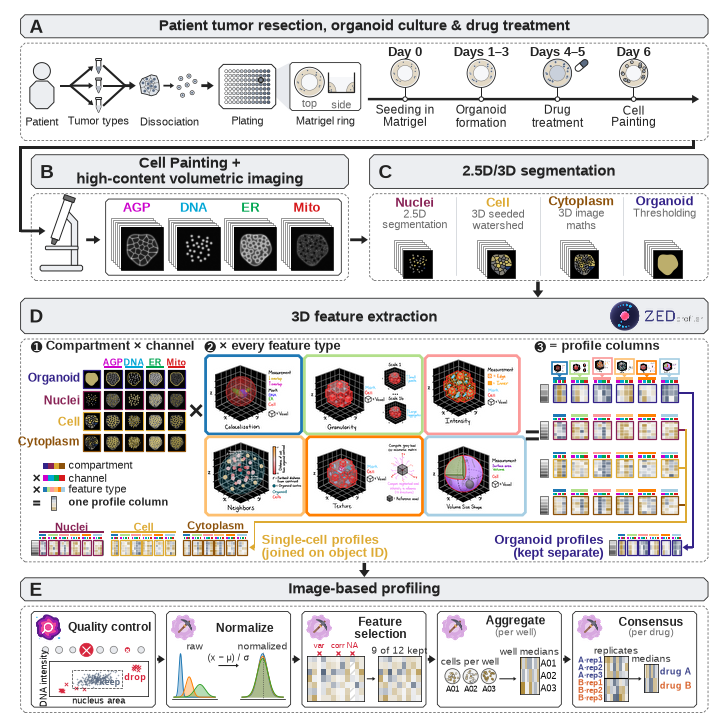

In [15]:
fig = build_figure()
plt.show()

## Export
Vector PDF and SVG keep text editable (Illustrator / Inkscape); the PNG is 600 dpi.

In [16]:
fig.savefig(f"{output_figure_file_path}", facecolor="white", dpi=600)